# Raghavan et al. 2021 — PDAC (Seq-Well)
## 02 · Cell-state manifold & trajectory

Honest topology test (PPT tree vs curve), then a fold-free principal **curve** on the developmental axis. Root is derived from the signatures' developmental order (Gast/pSom-high origin; Crest is late).

In [1]:
import os, sys, glob, io, contextlib
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scFates as scf
import matplotlib.pyplot as plt
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd()); cat = os.path.basename(os.path.dirname(os.getcwd()))
pth = os.path.join(*([os.pardir]*6)); pth_data = os.path.join(pth,'data')
pth_out = os.path.join(pth_data,'cancer','vertebrate','CCCA','Claude',cat,name)
pth_fig = os.path.join(pth,'figures','cancer','vertebrate','CCCA','Claude',cat,name)
pth_cb  = os.path.join(pth_fig,'colorbars'); os.makedirs(pth_cb, exist_ok=True)
pth_feat = os.path.join(pth_data,'features','biomart')

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out,'processed.h5ad'))
xy = adata.obsm['X_umap']; c = xy-xy.mean(0); _,s,_ = np.linalg.svd(c, full_matrices=False)
print('whole malignant manifold:', adata.shape[0], 'cells | UMAP aspect (major/minor std): %.2f' % (s[0]/s[1]))

whole malignant manifold: 7830 cells | UMAP aspect (major/minor std): 1.11


### Graph-smoothed module scores (for reading geography/order)
Smoothing aids the analysis; the deliverable signature UMAPs (03) show **raw** scores.

In [4]:
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src,lab in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,lab in enumerate(['Gast','pSom','Crest']): adata.obs[lab+'_sm'] = S[:,j]

Gast: 73/81 genes present
pSom: 85/98 genes present
Crest: 103/104 genes present


In [5]:
print('smoothed spatial correlations (whole manifold):')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    r = np.corrcoef(adata.obs[a], adata.obs[b])[0,1]; print(f'  {a} vs {b}: r = {r:+.2f}')
print('-> Gast & pSom co-vary; both oppose Crest. Single developmental axis, not two competing arms.')

smoothed spatial correlations (whole manifold):
  Gast_sm vs pSom_sm: r = +0.25
  Crest_sm vs Gast_sm: r = -0.75
  Crest_sm vs pSom_sm: r = -0.65
-> Gast & pSom co-vary; both oppose Crest. Single developmental axis, not two competing arms.


### Honest branching test — PPT tree first
Fit a PPT tree and inspect branch nodes **and their per-tip biology** on the embedding. A genuine bifurcation needs a Gast-arm vs pSom-arm split; radial tips of one identity over a round cloud do not.

In [6]:
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3: dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    tips = int(((B>0).sum(0)==1).sum()); forks = int(((B>0).sum(0)>=3).sum())
    return dmin/med, tips, forks
for Nodes in [30,50,80]:
    ad = adata.copy()
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.tree(ad, method='ppt', Nodes=Nodes, use_rep='X_umap', ppt_lambda=100, ppt_sigma=1.5, seed=SEED, plot=False)
        B = np.asarray(ad.uns['graph']['B'])
    print(f'PPT tree Nodes={Nodes}: {int(((B>0).sum(0)==1).sum())} tips, {int(((B>0).sum(0)>=3).sum())} branch nodes')
# per-tip biology on a representative tree
ad = adata.copy()
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.tree(ad, method='ppt', Nodes=50, use_rep='X_umap', ppt_lambda=100, ppt_sigma=1.5, seed=SEED, plot=False)
B = np.asarray(ad.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
hard = np.asarray(ad.obsm['X_R']).argmax(1); D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
print('per-tip biology (Nodes=50): all tips pSom-high / Crest-low, no Gast-vs-pSom split:')
for tp in tps:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    print(f'  tip {tp} (n={int(m.sum())}): Gast={ad.obs["Gast_sm"][m].mean():+.4f} pSom={ad.obs["pSom_sm"][m].mean():+.4f} Crest={ad.obs["Crest_sm"][m].mean():+.4f}')
print('-> branch-node count unstable across params (2-4) and all tips share one identity: NON-BRANCHING.')

PPT tree Nodes=30: 6 tips, 4 branch nodes
PPT tree Nodes=50: 8 tips, 6 branch nodes
PPT tree Nodes=80: 9 tips, 7 branch nodes
per-tip biology (Nodes=50): all tips pSom-high / Crest-low, no Gast-vs-pSom split:
  tip 13 (n=1081): Gast=-0.0329 pSom=+0.0714 Crest=-0.0130
  tip 25 (n=736): Gast=+0.0004 pSom=+0.0857 Crest=-0.0362
  tip 27 (n=549): Gast=+0.0023 pSom=+0.0806 Crest=-0.0365
  tip 28 (n=856): Gast=-0.0128 pSom=+0.0815 Crest=-0.0235
  tip 37 (n=881): Gast=-0.0052 pSom=+0.0758 Crest=-0.0341
  tip 41 (n=1012): Gast=-0.0332 pSom=+0.0721 Crest=-0.0136
  tip 43 (n=681): Gast=-0.0079 pSom=+0.0549 Crest=-0.0220
  tip 44 (n=1044): Gast=-0.0156 pSom=+0.0631 Crest=-0.0216
-> branch-node count unstable across params (2-4) and all tips share one identity: NON-BRANCHING.


### Fit the principal curve (non-branching) + fold check
Stiff, near-straight curve spanning the full developmental axis; verified fold-free (self-approach ratio > 1, 0 forks).

In [7]:
scf.tl.curve(adata, Nodes=20, use_rep='X_umap', epg_lambda=0.01, epg_mu=50, seed=SEED, plot=False)
sa, tips, forks = fold_diag(adata)
print(f'curve: {tips} tips, {forks} forks | fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
assert forks == 0 and sa > 1, 'topology check failed'

inferring a principal curve --> parameters used 
    20 principal points, mu = 50, lambda = 0.01
    finished (0:00:01) --> added 
    .uns['epg'] dictionnary containing inferred elastic curve generated from elpigraph.
    .obsm['X_R'] soft assignment of cells to principal points.
    .uns['graph']['B'] adjacency matrix of the principal points.
    .uns['graph']['F'], coordinates of principal points in representation space.
curve: 2 tips, 0 forks | fold self-approach ratio = 2.01 (>1 = fold-free)


### Derived root + pseudotime
Root at the Gast/pSom-high, Crest-low tip (developmental origin; Crest is late).

In [8]:
B = np.asarray(adata.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
hard = np.asarray(adata.obsm['X_R']).argmax(1); D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    info[tp] = (adata.obs['Gast_sm'][m].mean(), adata.obs['pSom_sm'][m].mean(), adata.obs['Crest_sm'][m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.4f} pSom={info[tp][1]:+.4f} Crest={info[tp][2]:+.4f}')
root = int(max(tps, key=lambda tp: info[tp][0]+info[tp][1]-info[tp][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(adata, root); scf.tl.pseudotime(adata, n_map=1, seed=SEED)
t = adata.obs['t'].values
print('gradient along pseudotime (Spearman rho, smoothed):')
for s in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,p = spearmanr(t, adata.obs[s]); print(f'  {s}: rho={rho:+.3f} p={p:.1e}')
print('root Gast/pSom-high -> terminus Crest-high: correct developmental order.')

tip 0: Gast=-0.0020 pSom=+0.0801 Crest=-0.0340
tip 2: Gast=-0.0120 pSom=+0.0614 Crest=-0.0217
derived root = tip 0 (Gast/pSom-high, Crest-low)
gradient along pseudotime (Spearman rho, smoothed):
  Gast_sm: rho=-0.403 p=4.3e-304
  pSom_sm: rho=-0.621 p=0.0e+00
  Crest_sm: rho=+0.515 p=0.0e+00
root Gast/pSom-high -> terminus Crest-high: correct developmental order.


In [9]:
# orientation consistency: pseudotime increases from origin(left) to terminus(right)
r = float(np.corrcoef(adata.obsm['X_umap_lin'][:,0], t)[0,1])
if r < 0:
    adata.obsm['X_umap_lin'][:,0] = -adata.obsm['X_umap_lin'][:,0]
    r = float(np.corrcoef(adata.obsm['X_umap_lin'][:,0], t)[0,1])
print(f'corr(X_umap_lin x, pseudotime) = {r:+.2f} (origin on left, terminus on right)')
assert r > 0.5

corr(X_umap_lin x, pseudotime) = +0.83 (origin on left, terminus on right)


### Save `manifold.h5ad` + `manifold.pdf`

saved manifold.h5ad + manifold.pdf


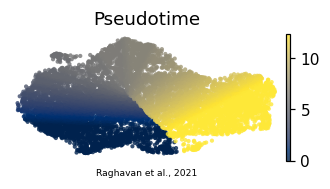

In [10]:
adata.uns['epg'] = {'NodePositions': np.asarray(adata.uns['epg']['NodePositions'])}
adata.write(os.path.join(pth_out,'manifold.h5ad'))
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'Raghavan et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
plt.show()
print('saved manifold.h5ad + manifold.pdf')